# Figure S24: Colocalization across QTL classes

Exclusive QTL-class intersections among colocalized gene-trait pairs.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig4_loci](../../preparation/Fig4/build_loci.R): Build exclusive UpSet intersections from unique gene-trait membership and join CD40 SuSiE variants to participating GWAS/QTL signals with original locus offsets and credible-set labels.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the exclusive intersections

Rebuild the S24 UpSet display from the saved exclusive intersection counts. The unit is a unique gene–trait pair. The internal union layer is excluded. No GWAS or colocalization analysis is run.


In [2]:
intersections <- readr::read_tsv(source_file("Fig4/coloc_upset_intersection_counts.tsv"), show_col_types = FALSE) %>%
  arrange(desc(gene_trait_pairs)) %>% mutate(index = row_number(), sets = strsplit(qtl_combination, "+", fixed = TRUE),
                                            n_sets = lengths(sets), multilayer = n_sets >= 2)
stopifnot(nrow(intersections) == 7L,
          sum(intersections$gene_trait_pairs[intersections$multilayer]) == 1617L)
qtl_sets <- c("eQTL", "pQTL", "sQTL")


## Reconstruct the aggregate UpSet matrix

One column is one exclusive QTL combination. Filled dots identify its component assays. The top bars give the saved exclusive counts. The side bars sum all combinations that contain an assay. No membership rows are fabricated or expanded.


In [3]:
matrix <- tidyr::crossing(index = intersections$index, assay = qtl_sets) %>%
  left_join(intersections %>% select(index, sets), by = "index") %>%
  mutate(active = purrr::map2_lgl(assay, sets, ~.x %in% .y),
         y = match(assay, rev(qtl_sets)))
connectors <- matrix %>% filter(active) %>% group_by(index) %>%
  summarise(low = min(y), high = max(y), .groups = "drop")
set_sizes <- matrix %>% filter(active) %>%
  left_join(intersections %>% select(index, gene_trait_pairs), by = "index") %>%
  group_by(assay, y) %>% summarise(gene_trait_pairs = sum(gene_trait_pairs), .groups = "drop")
bars <- ggplot(intersections, aes(index, gene_trait_pairs, fill = multilayer)) +
  geom_col(width = 0.65) + geom_text(aes(label = scales::comma(gene_trait_pairs)), vjust = -0.35, size = 2.8) +
  scale_fill_manual(values = c(`FALSE` = "#2F5597", `TRUE` = "#CC79A7"), guide = "none") +
  scale_x_continuous(limits = c(0.4, 7.6), breaks = NULL, expand = expansion(mult = 0)) +
  scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.12))) +
  labs(x = NULL, y = "Gene–trait pairs per QTL combination") + theme_classic(base_size = 9) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank())
dots <- ggplot(matrix, aes(index, y)) +
  geom_point(size = 2.5, colour = "#DDDDDD") +
  geom_segment(data = connectors, aes(x = index, xend = index, y = low, yend = high), inherit.aes = FALSE, linewidth = 0.7) +
  geom_point(data = filter(matrix, active), size = 2.5, colour = "#333333") +
  scale_x_continuous(limits = c(0.4, 7.6), breaks = NULL, expand = expansion(mult = 0)) +
  scale_y_continuous(limits = c(0.5, 3.5), breaks = 1:3, labels = rev(qtl_sets), expand = expansion(mult = 0)) +
  labs(x = NULL, y = NULL) + theme_void(base_size = 9) + theme(axis.text.y = element_text())
totals <- ggplot(set_sizes, aes(gene_trait_pairs, y, fill = assay)) +
  geom_col(orientation = "y", width = 0.55) +
  scale_fill_manual(values = c(eQTL = "#0072B2", pQTL = "#D55E00", sQTL = "#009E73"), guide = "none") +
  scale_x_reverse(labels = scales::label_comma()) +
  scale_y_continuous(limits = c(0.5, 3.5), breaks = NULL, expand = expansion(mult = 0)) +
  labs(x = "Gene–trait pairs", y = NULL) + theme_classic(base_size = 8) +
  theme(axis.line.y = element_blank(), axis.ticks.y = element_blank())


## Display and save the aggregate intersections

Pink bars identify combinations with at least two QTL classes. This native ggplot layout uses the same exclusive intersections as the original UpSetR display. It does not require the upstream gene–trait membership file.


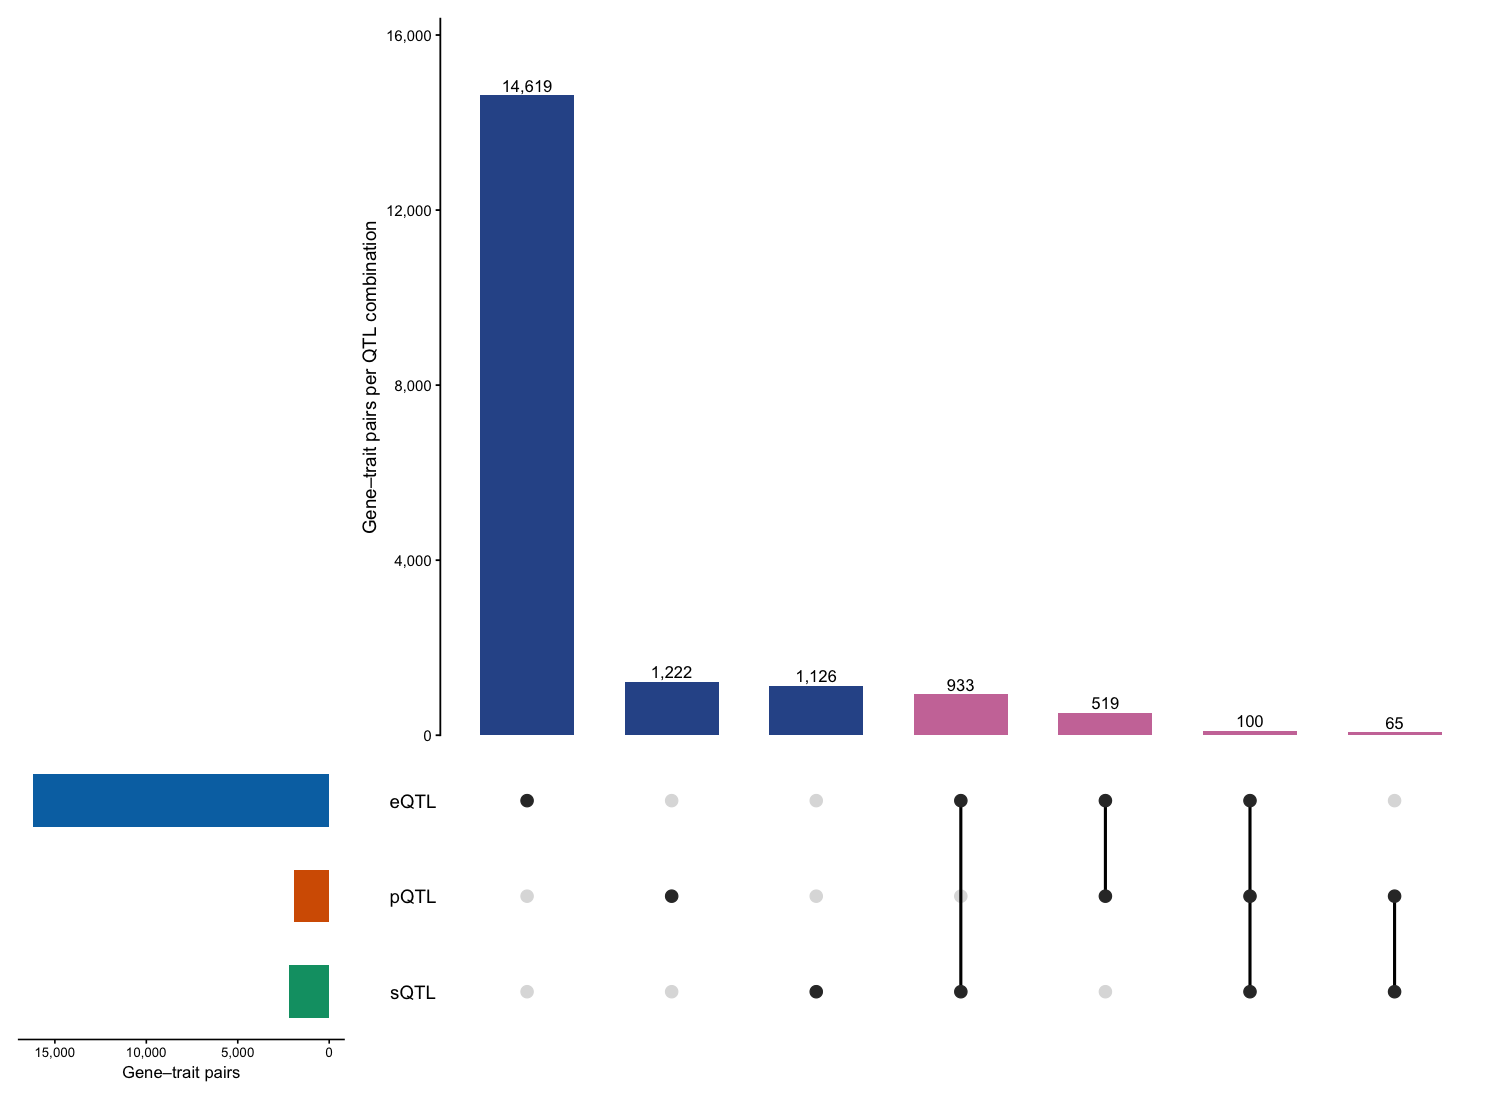

Export aggregate plot: supplements/S24


In [4]:
figure <- patchwork::plot_spacer() + bars + totals + dots +
  patchwork::plot_layout(ncol = 2, widths = c(1, 3.2), heights = c(3, 1.2))
print(figure)
save_plot(figure, "supplements/S24", 184, 145)
readr::write_tsv(intersections %>% select(qtl_combination, gene_trait_pairs, n_sets), output_file("supplements/S24_intersections.tsv"))
